In [37]:
!pip install opencv-python

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [39]:
img = cv2.imread('nic.png')
type(img), img.shape

(numpy.ndarray, (117, 429, 3))

In [50]:
cv2.imshow("Original Image", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

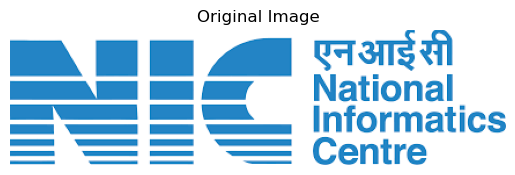

In [41]:
img = plt.imread("nic.png")

plt.figure()
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [46]:
new_width = 200
new_height = 200
resized_img = cv2.resize(img, (new_width, new_height), interpolation=cv2.INTER_AREA)
resized_img.shape

(200, 200, 4)

In [49]:
cv2.imshow("Resized Image", resized_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

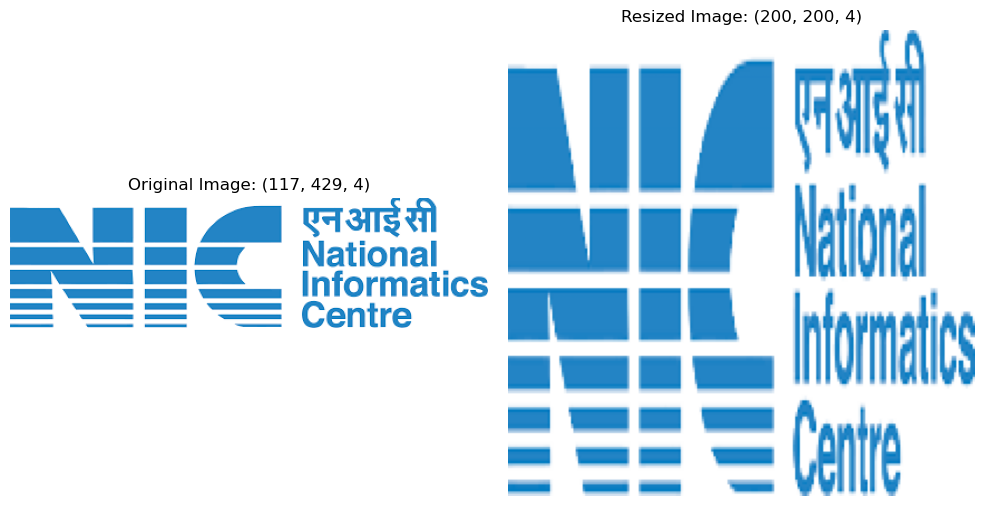

In [48]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(f"Original Image: {img.shape}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img)
plt.title(f"Resized Image: {resized_img.shape}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
print("Minimum Pixel Value:", img.min())
print("Maximum Pixel Value:", img.max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [52]:
flip = cv2.flip(img, 0)  # Flip vertically
flip.shape

(117, 429, 4)

In [53]:
cv2.imshow("Flipped Image", flip)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [55]:
img_crop=img[100:300,200:500]

In [61]:
cv2.imshow("Cropped Image", img_crop)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [62]:
cv2.imwrite("resized_image.png", img_crop)

True

In [64]:
# !pip install ultralytics

In [66]:
import cv2
from ultralytics import settings

# Disable data and crash report tracking
settings.update({"sync": False})

from ultralytics import YOLO

# 1. Load the lightweight YOLOv8 Nano model (~6MB, runs fast on CPU)
model = YOLO('yolov8n.pt')

# 2. Open the webcam (0 is default built-in camera)
cap = cv2.VideoCapture(0)

print("Starting Object Counter... Press 'q' on the video window to quit.")

while cap.isOpened():
  success, frame = cap.read()
  if not success:
    print("Failed to grab camera frame.")
    break

  # 3. Perform object detection on the current frame
  results = model(frame, verbose=False)

  # Get total number of objects detected in this frame
  detected_count = len(results[0].boxes)

  # 4. Render detection boxes directly on the frame
  annotated_frame = results[0].plot()

  # 5. Display the object count overlay on screen
  cv2.putText(
      annotated_frame,
      f'Total Objects Counted: {detected_count}',
      (20, 50),  # Position (x, y)
      cv2.FONT_HERSHEY_SIMPLEX,
      1,  # Font scale
      (0, 255, 0),  # Text color (Green)
      2,  # Thickness
      cv2.LINE_AA,
  )

  # 6. Show the frame in a window
  cv2.imshow('BCA AI Demo - Live Object Counter', annotated_frame)

  # 7. Terminate program cleanly when pressing 'q'
  if cv2.waitKey(1) & 0xFF == ord('q'):
    print("Terminating program...")
    break

# Release camera and close all windows cleanly
cap.release()

# 2. Add short wait key loops to let Windows pump destroy events cleanly
cv2.waitKey(1)
cv2.destroyAllWindows()
cv2.waitKey(1)

print("Camera feed closed successfully.")

Starting Object Counter... Press 'q' on the video window to quit.
Terminating program...
Camera feed closed successfully.
